<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="../592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography homework</div>
    </div>
</div>

In [ ]:
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify

### Background
I will look at the range of red squirrels vs. grey squirrels in the UK. Red squirrels are native to the UK, and grey squirrels are an invasive species introduced in the late 1800s. Grey squirrels outcompete red squirrels, and grey squirrels are also a carrier for a virus that is highly fatal to red squirrels. As a result, grey squirrels have gradually been pushing red squirrels out of the UK woodlands. Drawing from this background information, I would like to see how the current ranges of the two squirrels compare and where there is overlap. \
Source: https://www.discoverwildlife.com/animal-facts/mammals/red-squirrel-vs-grey-squirrel-differences 

### Credits
Most code modified from the Mulberry Map JN by Javier Arce-Nazario

### Importing data
European red squirrel: Sciurus vulgaris \
Eastern grey squirrel: Sciurus carolinensis \
I am importing records for October through December for 2026 since there is a large amount of data for 2026. 

In [3]:
# This cell might take some time to execute.
# https://www.gbif.org/

species = ["Sciurus vulgaris", "Sciurus carolinensis"]
year = 2025

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # 1. Find the GBIF taxon identifier for the scientific name.
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if (
        match.get("matchType") != "EXACT"
        or match.get("rank") != "SPECIES"
    ):
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    # 2. Define which occurrence records to request.
    parameters = {
        "taxonKey": taxon_key,
        # Two letter country code, GB for Great Britain.
        "country": "GB",
        "year": year,
        "month": [10, 11, 12],
        "basisOfRecord": "HUMAN_OBSERVATION",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    # 3. Retrieve successive pages of records.
    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        # LIMIT THE NUMBER OF CASES (you can change it but, the larger the number...the longer the wait)
        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records for this example. "
                "Narrow the date range or use a GBIF bulk download."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)
    print(f"{name}: {len(species_records):,} records")


Sciurus vulgaris: 4,604 records
Sciurus carolinensis: 8,596 records


In [4]:
squirrels = pd.DataFrame(records)
squirrels = squirrels[["queried_species", "decimalLongitude", "decimalLatitude"]] 
squirrels.head()

,queried_species,decimalLongitude,decimalLatitude
0,Sciurus vulgaris,-3.592305,56.564980
1,Sciurus vulgaris,-4.319025,53.259914
2,Sciurus vulgaris,-4.311675,53.263357
3,Sciurus vulgaris,-3.842277,56.769984
4,Sciurus vulgaris,-3.054846,54.440317


<Axes: >

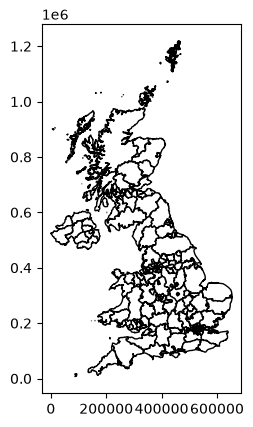

In [5]:
uk_original = gpd.read_file("uk_counties.geojson")
# 7405 is the national grid of Great Britain
uk = uk_original.to_crs(epsg=7405)
uk = uk.rename(columns={"CTYUA24NM":"name"})[["FID", "name", "geometry"]]
uk.plot(edgecolor="black", facecolor="white")

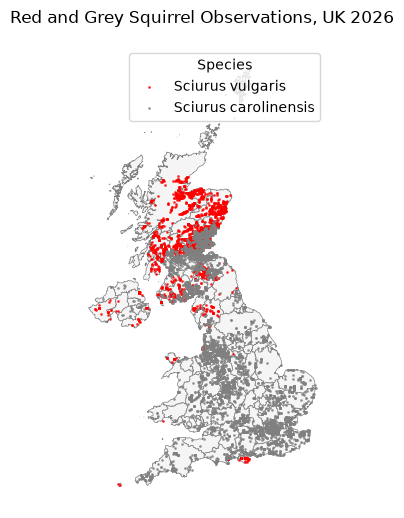

In [6]:
# Making a gdp from the x and y data. 

squirrels_points = gpd.GeoDataFrame(
    squirrels.copy(),
    geometry=gpd.points_from_xy( ## the method is calleed points_from_xy
        squirrels["decimalLongitude"], # x
        squirrels["decimalLatitude"] # y
        ),
    crs="EPSG:4326" # often the crs is in 4326 if it is a lat lon coordinate
    )

squirrels_points = squirrels_points.to_crs(epsg=7405)

fig, ax = plt.subplots(figsize=(12, 6))
uk.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Sciurus vulgaris": "red", "Sciurus carolinensis": "grey"}

for species, color in colors.items():
    squirrels_points.loc[
        squirrels_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=1,
        alpha=0.7,
        label=species
    )

ax.set_title("Red and Grey Squirrel Observations, UK 2026")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

### Comparing classification schemes

In [7]:
# Joins sqiurrel points within each county.
points_by_county = gpd.sjoin(
    squirrels_points,
    uk[["name", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_county.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,name
0,Sciurus vulgaris,-3.592305,56.564980,POINT (302245.785 742581.738),Perth and Kinross
1,Sciurus vulgaris,-4.319025,53.259914,POINT (245410.345 376166.609),Isle of Anglesey
2,Sciurus vulgaris,-4.311675,53.263357,POINT (245912.929 376533.67),Isle of Anglesey
3,Sciurus vulgaris,-3.842277,56.769984,POINT (287499.239 765780.968),Perth and Kinross
4,Sciurus vulgaris,-3.054846,54.440317,POINT (331684.106 505502.241),Westmorland and Furness


In [8]:
counts = (
    points_by_county
    .groupby(["name", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Sciurus vulgaris", "Sciurus carolinensis"], fill_value=0)
)
counts.head()

queried_species,Sciurus vulgaris,Sciurus carolinensis
name,,
Aberdeen City,284,0
Aberdeenshire,460,2
Angus,415,233
Antrim and Newtownabbey,0,3
Ards and North Down,18,6


In [9]:
def choroplethMap(ax, uk, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total")

    # Join totals to the country polygons.
    county_map = uk.merge(
        totals,
        left_on="name",
        right_index=True,
        how="left"
    )

    # Countries without records receive zero.
    county_map["total"] = county_map["total"].fillna(0)

    county_map.plot(
        column="total",
        cmap="RdPu", # This color was selected by me not AI 
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Squirrel observations by state")
    ax.set_axis_off()

    return ax

In [10]:
def choroplethEqual(ax, uk, counts):
    totals = counts.sum(axis=1).rename("total")

    county_map = uk.merge(
        totals, left_on="name", right_index=True, how="left"
    )
    county_map["total"] = county_map["total"].fillna(0)

    county_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Equal interval")
    ax.set_axis_off()
    return ax

def choroplethQuantiles(ax, uk, counts):
    totals = counts.sum(axis=1).rename("total")

    county_map = uk.merge(
        totals, left_on="name", right_index=True, how="left"
    )
    county_map["total"] = county_map["total"].fillna(0)

    county_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Quantiles")
    ax.set_axis_off()
    return ax

def choroplethNatural(ax, uk, counts):
    totals = counts.sum(axis=1).rename("total")

    county_map = uk.merge(
        totals, left_on="name", right_index=True, how="left"
    )
    county_map["total"] = county_map["total"].fillna(0)

    county_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks)")
    ax.set_axis_off()
    return ax

c:\Users\Abigail\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\geopandas\plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


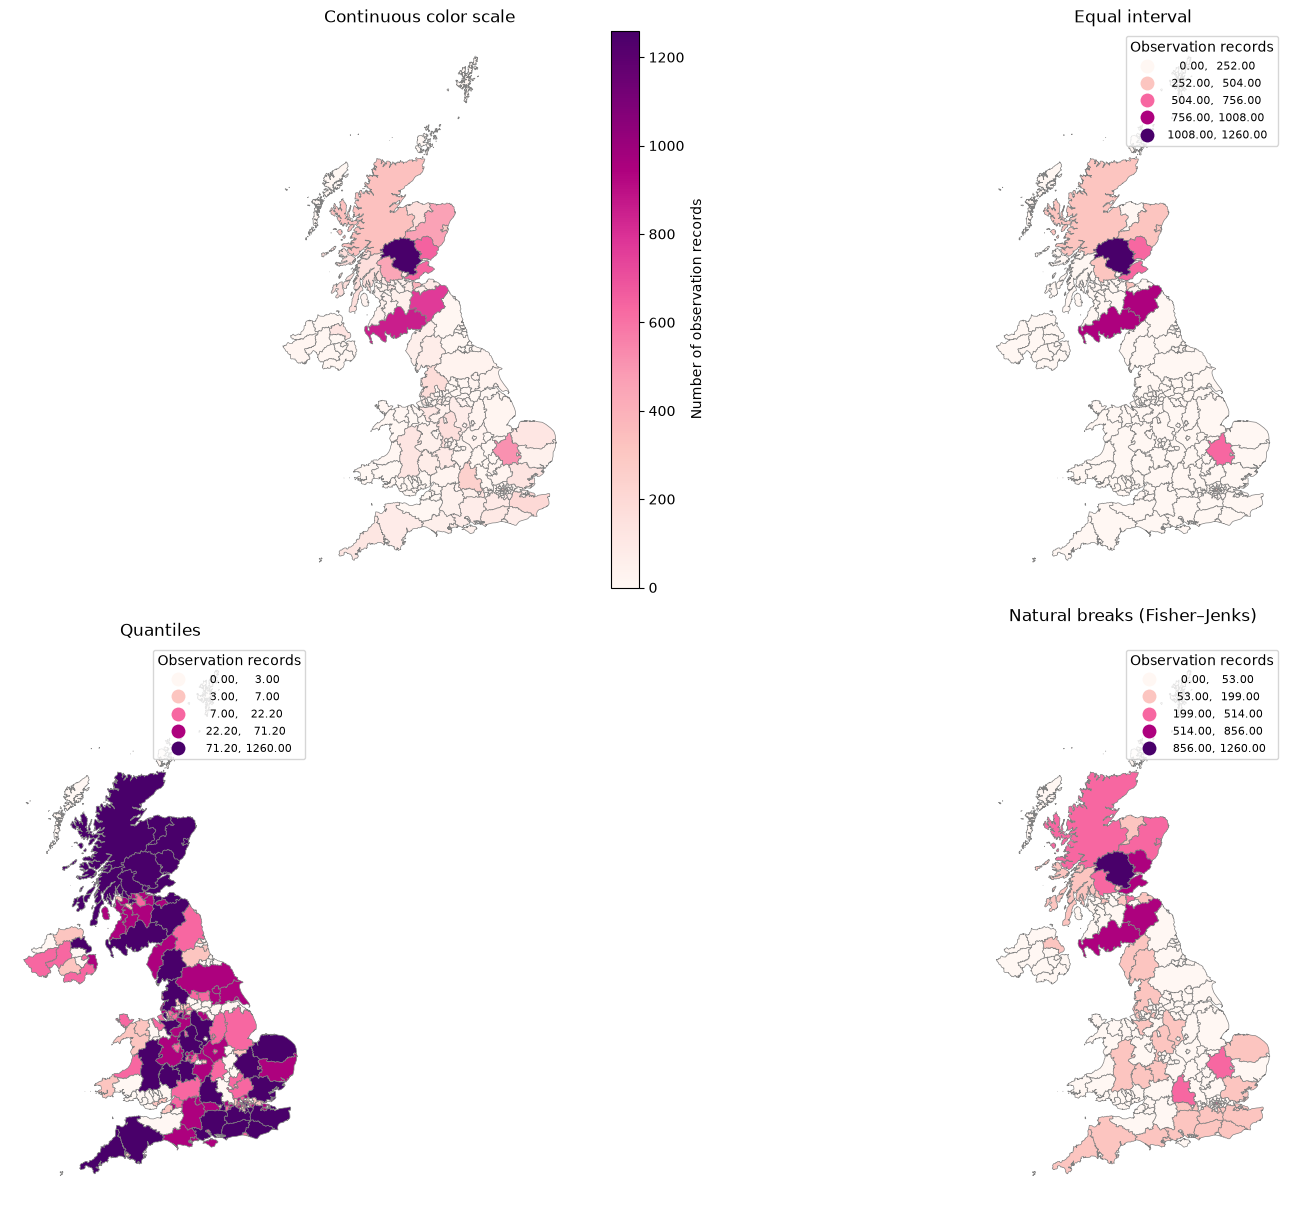

In [11]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

choroplethMap(axes[0, 0], uk, counts)
axes[0, 0].set_title("Continuous color scale")

choroplethEqual(axes[0, 1], uk, counts)
choroplethQuantiles(axes[1, 0], uk, counts)
choroplethNatural(axes[1, 1], uk, counts)

# fig.savefig("mulberry_classification.png", dpi=300, bbox_inches="tight")
# fig.savefig("mulberry_classification.pdf", bbox_inches="tight")

plt.show()

### Classfication scheme analysis 
A map with **no classification** scheme may look nice aesthetically, but it is hard to tell which polygons match up with what values. \
Since my data is skewed left, **equal interval** produces a map with not much differentiation at the lower end of the range. \
**Quantiles** produces an even distribution of the five colors, but it may misrepresent the frequency of some categories, in this case making higher values seem more common. \
**Natural breaks** is a good compromise between represententing frequency correctly while differentiating between the data on the skewed end. 

### Bivariate map

Sciurus vulgaris positive-count median: 19.0
Sciurus carolinensis positive-count median: 15.0


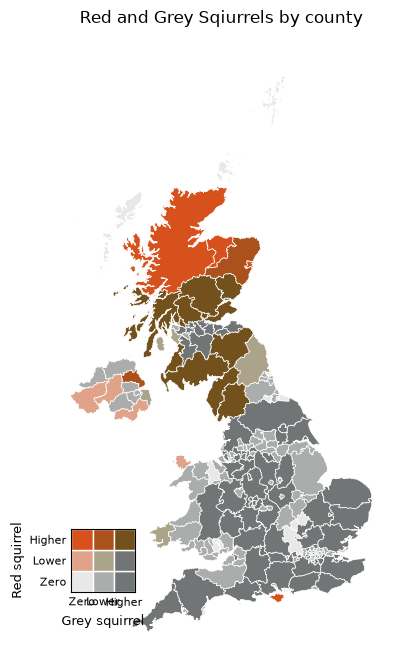

In [12]:
import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons.
bivariate = uk.merge(
    counts,
    left_on="name",
    right_index=True,
    how="left"
)

species = ["Sciurus vulgaris", "Sciurus carolinensis"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

# Rows represent increasing red squirrel counts.
# Columns represent increasing grey squirrel counts.
palette = np.array([
    ["#e8e8e8", "#abadad", "#727575"], 
    ["#e0a38a", "#aba38a", "#727575"], 
    ["#d6511c", "#ab511c", "#72511c"]
])

bivariate["color"] = [
    palette[red, white]
    for red, white in zip(
        bivariate["Sciurus vulgaris_class"],
        bivariate["Sciurus carolinensis_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title("Red and Grey Sqiurrels by county")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend.
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for red in range(3):
    for white in range(3):
        legend_ax.add_patch(
            Rectangle(
                (white, red), 1, 1,
                facecolor=palette[red, white],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("Grey squirrel", fontsize=9)
legend_ax.set_ylabel("Red squirrel", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

# Saving the figure as a png
fig.savefig("sqiurrel_bivariate.png", bbox_inches="tight")

### Proportional symbol map 

Making a gpd with the totals for each polygon because the code for this is inside the mapping functions right now. 

In [27]:
# Join totals to each polygon 
# Counts has the total number for both species 
# axis=1 takes the sum along each row
totals = counts.sum(axis=1).rename("total")
totals.head()

name
Aberdeen City              284
Aberdeenshire              462
Angus                      648
Antrim and Newtownabbey      3
Ards and North Down         24
Name: total, dtype: int64

In [75]:
# Joining the totals to the UK polygons 
squirrel_totals = uk.merge(totals,
    left_on="name",
    right_index=True,
    how="left"
)

# Replacing NaNs 
squirrel_totals['total'] = squirrel_totals['total'].fillna(0)
squirrel_totals.head()

,FID,name,geometry,total
0,1,Hartlepool,"POLYGON ((448963.152 536758.332, 448985.072 53...",3.0
1,2,Middlesbrough,"POLYGON ((451893.38 521146.732, 453996.798 517...",0.0
2,3,Redcar and Cleveland,"POLYGON ((478231.885 518790.302, 477688.241 51...",0.0
3,4,Stockton-on-Tees,"POLYGON ((452242.605 526336.474, 451710.371 52...",3.0
4,5,Darlington,"POLYGON ((436387.259 522355.444, 437350.924 52...",0.0


Visualizing centroids

<Axes: >

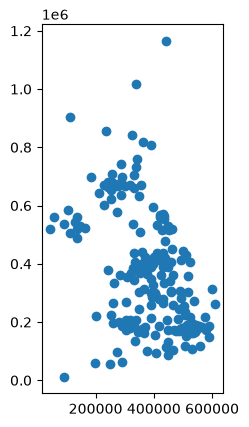

In [76]:
centers = uk.geometry.centroid
centers.plot()

Doing some exploration of what mapclassify does.

In [82]:
# Calculates what the intervals are for 3 categories using Fisher Jenks 
classification = mapclassify.FisherJenks(
        squirrel_totals["total"],
        k=3
    )

print(classification)
print(classification.yb)

FisherJenks

     Interval        Count
--------------------------
[   0.00,  199.00] |   205
( 199.00,  648.00] |    10
( 648.00, 1260.00] |     3
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 1 0 0 0 0 0 2 0 0 0 1 1 1 0
 1 0 0 0 1 0 0 1 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


C:\Users\Abigail\AppData\Roaming\Python\Python314\site-packages\IPython\core\interactiveshell.py:3775: UserWarning: Numba not installed. Using slow pure python version.
  exec(code_obj, self.user_global_ns, self.user_ns)


Classify and map 

In [ ]:
def propSymbol_class(ax):

    # Gets the positive values. 
    positive = squirrel_totals.loc[squirrel_totals["total"] > 0].copy()
    # Getting the centroids for the positive values. 
    centers = positive.geometry.centroid

    # Classifying into three categories using the positive totals. 
    classification = mapclassify.FisherJenks(
        positive["total"],
        k=3
    )

    # Plots the county geometries that are in the squirrel_totals dataframe. 
    squirrel_totals.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    # Circle areas for low, medium, and high classes.
    sizes = np.array([60, 250, 700])

    # scatter plots points based on x and y positions. 
    ax.scatter(
        centers.x,
        centers.y,
        # yb has a number showing which categories the observation is in. 
        s=sizes[classification.yb], 
        color="#8e235c",
        alpha=0.6,
        edgecolors="white",
        linewidths=0.5
    )

    # Build the legend using the actual count range in each class.
    # enumerate() returns pairs as (index, element)
    for class_id, size in enumerate(sizes):
        values = positive.loc[
            classification.yb == class_id, "total"
        ]

        # Adding the circles in the legend 
        ax.scatter(
            [], [],
            s=size,
            color="#8e235c",
            alpha=0.6,
            edgecolors="white",
            label=f"{values.min():,.0f}–{values.max():,.0f}"
        )

    # Legend styling
    ax.legend(
        title="Observation records",
        loc="upper right",
        labelspacing=1.5
    )
    # Returns the plot as an axes object to where the function was a called. 
    return ax

C:\Users\Abigail\AppData\Local\Temp\ipykernel_24016\1700882702.py:2: UserWarning: Numba not installed. Using slow pure python version.
  ax = propSymbol_class(ax)


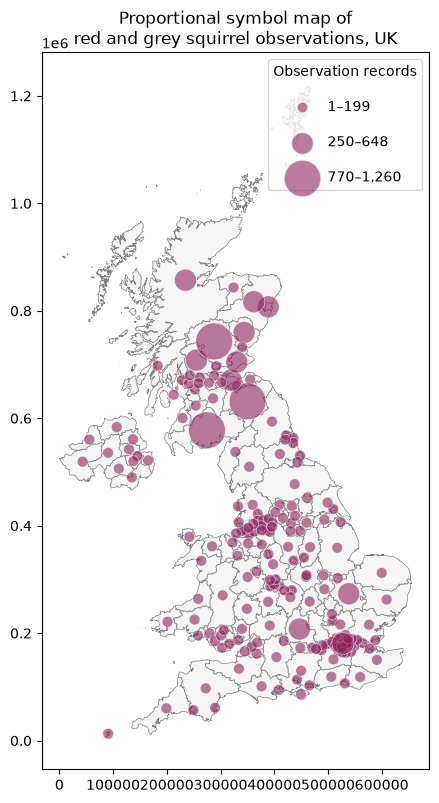

In [ ]:
# This doesn't visualize well where there are clusters of small counties, such as around London. 
# I would probably use different borders in the future, based on similar area and not population. 
fig, ax = plt.subplots(figsize=(5, 10)) 
ax = propSymbol_class(ax)
ax.set_title("Proportional symbol map of\nred and grey squirrel observations, UK")
plt.show()

### Hexagon map

In [85]:
from shapely.geometry import Polygon

# Equal-area projection with coordinates in meters.
states = uk
points = points_by_county.copy()

# Hexagon size: center to vertex, in meters.
radius = 100000

xmin, ymin, xmax, ymax = states.total_bounds
hexagons = []

for column, x in enumerate(
    np.arange(xmin - radius, xmax + 2 * radius, 1.5 * radius)
):
    for y in np.arange(
        ymin - radius, ymax + 2 * radius, np.sqrt(3) * radius
    ):
        # Offset alternating columns.
        center_y = y + (column % 2) * np.sqrt(3) * radius / 2

        angles = np.arange(6) * np.pi / 3

        hexagons.append(
            Polygon([
                (
                    x + radius * np.cos(angle),
                    center_y + radius * np.sin(angle)
                )
                for angle in angles
            ])
        )

grid = gpd.GeoDataFrame(
    {"hex_id": range(len(hexagons))},
    geometry=hexagons,
    crs=states.crs
)

# Keep hexagons that intersect the UK.
region = states.geometry.union_all()
grid = grid.loc[grid.intersects(region)].copy()

# Assign each observation to a hexagon.
points = points.reset_index(drop=True)
points["point_id"] = points.index

joined = gpd.sjoin(
    points,
    grid[["hex_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

# Count an observation only once if it falls exactly on a shared edge.
joined = (
    joined.sort_values("hex_id")
    .drop_duplicates("point_id")
)

# Count records by hexagon and species.
hex_counts = (
    joined.groupby(["hex_id", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Sciurus vulgaris", "Sciurus carolinensis"], fill_value=0)
)

grid = grid.merge(
    hex_counts,
    left_on="hex_id",
    right_index=True,
    how="left"
)

species = ["Sciurus vulgaris", "Sciurus carolinensis"]
grid[species] = grid[species].fillna(0)
grid["total"] = grid[species].sum(axis=1)

In [105]:
from matplotlib.patches import Rectangle

def hexBivariateMap(ax, grid, states):
    mapped = grid.copy()

    for name in ["Sciurus vulgaris", "Sciurus carolinensis"]:
        values = mapped[name]
        median = values.loc[values > 0].median()

        mapped[name + "_class"] = np.select(
            [values == 0, values <= median],
            [0, 1],
            default=2
        )

    # Rows: increasing red mulberry.
    # Columns: increasing white mulberry.
    palette = np.array([
    ["#e8e8e8", "#abadad", "#727575"], 
    ["#e0a38a", "#aba38a", "#727575"], 
    ["#d6511c", "#ab511c", "#72511c"]
    ])

    mapped["color"] = [
        palette[red, white]
        for red, white in zip(
            mapped["Sciurus vulgaris_class"],
            mapped["Sciurus carolinensis_class"]
        )
    ]

    mapped.plot(
        ax=ax,
        color=mapped["color"],
        edgecolor="white",
        linewidth=0.2
    )

    states.boundary.plot(ax=ax, color="gray", linewidth=0.4)

    legend_ax = ax.inset_axes([0.05, 0.05, 0.18, 0.23])

    for red in range(3):
        for white in range(3):
            legend_ax.add_patch(
                Rectangle(
                    (white, red), 1, 1,
                    facecolor=palette[red, white],
                    edgecolor="white"
                )
            )

    legend_ax.set_xlim(0, 3)
    legend_ax.set_ylim(0, 3)
    legend_ax.set_aspect("equal")
    legend_ax.set_xticks([0.5, 1.5, 2.5])
    legend_ax.set_yticks([0.5, 1.5, 2.5])
    legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=7)
    legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=7)
    legend_ax.set_xlabel("Grey squirrel", fontsize=8)
    legend_ax.set_ylabel("Red squirrel", fontsize=8)
    legend_ax.tick_params(length=0)

    ax.set_title("Red and grey squirrel observations")
    ax.set_axis_off()
    return ax

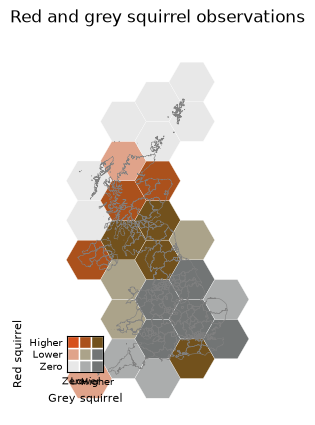

In [106]:
fig, ax = plt.subplots()

hexBivariateMap(ax, grid, states)

plt.show()